**Table of contents**<a id='toc0_'></a>    
- [Preparing environment](#toc1_)    
- [Data import](#toc2_)    
- [Hyperparameters optimization for different models](#toc3_)    
  - [Splitting the train and test sets](#toc3_1_)    
  - [Model and parameters selection](#toc3_2_)    
  - [Grid search](#toc3_3_)    
  - [Adding XGBoost](#toc3_4_)    
  - [Optimizing XGBoost with penalization](#toc3_5_)    
- [Evaluating models](#toc4_)    
  - [Final model training and saving](#toc4_1_)    
    - [Final training](#toc4_1_1_)    
    - [Confusion matrix](#toc4_1_2_)    
    - [Writing the pipeline to the disk](#toc4_1_3_)    
  - [Features importance](#toc4_2_)    
    - [Feature importance extraction from the XGBoost model](#toc4_2_1_)    
  - [Evaluate model with less features](#toc4_3_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

# <a id='toc1_'></a>[Preparion de l'environment](#toc0_)

In [2]:
import joblib
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    hamming_loss,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

c:\Users\hp\Documents\Master_SISE\Cours_Python-A. Sardellitti\Projet_Enedis\App_Enedis\.env-enedis\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Global variable to avoid rerunning cells.
IGNORE = False  # Set to False to run all cells.

# <a id='toc2_'></a>[Data import](#toc0_)

In [4]:
df = pd.read_csv("output/cleaned_data.csv")

In [5]:
# obtenir rid des colonnes non feature
df = df.drop(
    columns=[
        "code_insee_ban",
        "code_departement_ban",
        "code_postal_ban",
        "lat",
        "lon",
        "nom_commune_ban",
    ]
)

In [6]:
df

,cout_total_5_usages,type_energie_principale_chauffage,surface_habitable_logement,nombre_niveau_logement,type_batiment,etiquette_dpe,age_batiment,zone_climatique,altitude_moyenne
0,946.3,Autre,58.0,1.0,appartement,C,57.0,H1,35.0
1,724.5,Électricité,30.0,1.0,appartement,D,79.0,H1,35.0
2,761.6,Électricité,10.8,1.0,appartement,F,51.0,H1,35.0
3,946.8,Électricité,70.0,1.0,appartement,C,78.0,H1,35.0
4,1246.0,Électricité,34.7,1.0,appartement,E,392.0,H1,35.0
...,...,...,...,...,...,...,...,...,...
616052,879.2,Autre,93.7,1.0,maison,B,0.0,H2,1026.0
616053,514.0,Autre,89.9,1.0,maison,A,0.0,H2,1224.0
616054,518.0,Autre,124.6,1.0,maison,A,0.0,H2,899.0
616055,568.3,Autre,96.2,1.0,maison,A,0.0,H2,899.0


In [7]:
# Specification des features quantitatives et qualitatives.
quantitative_features = [
    "cout_total_5_usages",
    "surface_habitable_logement",
    "nombre_niveau_logement",
    "age_batiment",
    "altitude_moyenne",
]

qualitative_features = [
    "type_energie_principale_chauffage",
    "type_batiment",
    "zone_climatique",
]

target = "etiquette_dpe"

In [8]:
# Separation des features et target.
X = df[quantitative_features + qualitative_features]
y = df[target]

# <a id='toc3_'></a>[Optimisation des hyperparamètres pour différents modèles](#toc0_)

## <a id='toc3_1_'></a>[Séparation des ensembles d’entraînement et de test](#toc0_)

In [9]:
# Separation des données en ensembles d'entraînement et de test avec stratification. (70/30).
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.3, stratify=y)

In [10]:
print(len(Xtrain), len(Xtest))

431239 184818


In [11]:
ytrain.value_counts(normalize=True)

etiquette_dpe
C    0.305063
A    0.253497
D    0.168422
B    0.110389
E    0.099852
F    0.039094
G    0.023683
Name: proportion, dtype: float64

In [12]:
ytest.value_counts(normalize=True)

etiquette_dpe
C    0.305062
A    0.253498
D    0.168425
B    0.110390
E    0.099850
F    0.039093
G    0.023683
Name: proportion, dtype: float64

## <a id='toc3_2_'></a>[Sélection du modèle et des paramètres](#toc0_)

In [13]:
models = {
    "Logistic Regression": LogisticRegression(),
    "qda": QuadraticDiscriminantAnalysis(),
    "Random Forest": RandomForestClassifier(),
    "KNN": KNeighborsClassifier(),
}

param_grids = {
    "Logistic Regression": {
        "model__C": [0.1, 0.5, 1, 10],
        "model__penalty": ["elasticnet", None],
        "model__solver": ["saga"],
        "model__l1_ratio": [0.25, 0.5, 0.75],
    },
    "qda": {"model__reg_param": [0.0, 0.1, 0.5]},
    "Random Forest": {
        "model__n_estimators": [50, 100],
        "model__max_depth": [None, 5, 10],
        "model__min_samples_split": [2, 20],
    },
    "KNN": {
        "model__n_neighbors": [3, 5],
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2],
    },
}

# Liste des modèles qui nécessitent une mise à l’échelle des variables (feature scaling)
enforce_scaling = ["Logistic Regression", "qda", "KNN"]

## <a id='toc3_3_'></a>[Recherche par grille (Grid Search)](#toc0_)

In [14]:
if not IGNORE:
    # Creating an MLflow experiment.
    mlflow.set_experiment("Hyperparameter Tuning Classification Models")

    # Boucle sur les modèles
    for name, model in models.items():
        # MLflow run
        with mlflow.start_run(run_name=name):
            print("Training model:", name)

            # Standardization for non trees models.
            if name in enforce_scaling:
                preprocessor = ColumnTransformer(
                    transformers=[
                        (
                            "scaler",
                            StandardScaler(),
                            quantitative_features,
                        ),  # Standardize only quantitatives.
                        (
                            "encoder",
                            OneHotEncoder(),
                            qualitative_features,
                        ),  # OneHot encoding for qualitatives.
                    ]
                )

            else:
                preprocessor = ColumnTransformer(
                    transformers=[("encoder", OneHotEncoder(), qualitative_features)]
                )

            pipeline = Pipeline(
                steps=[("preprocessor", preprocessor), ("model", models[name])]
            )

            # GridSearchCV
            grid = GridSearchCV(
                pipeline,
                param_grids[name],
                cv=5,
                scoring="balanced_accuracy",
                n_jobs=-1,
            )
            grid.fit(Xtrain, ytrain)

            # Best scores and parameters
            best_params = grid.best_params_
            best_score = grid.best_score_
            ypred = grid.predict(Xtest)
            acc = accuracy_score(ytest, ypred)
            balanced_acc = balanced_accuracy_score(ytest, ypred)
            f1 = f1_score(ytest, ypred, average="weighted")

            # Logging MLflow
            mlflow.log_params(best_params)  # Hyperparameters
            mlflow.log_metric("best_cv_score", best_score)
            mlflow.log_metric("test_accuracy", float(acc))
            mlflow.log_metric("test_f1_score", float(f1))
            mlflow.log_metric("test_balanced_accuracy", float(balanced_acc))

Training model: Logistic Regression


c:\Users\hp\Documents\Master_SISE\Cours_Python-A. Sardellitti\Projet_Enedis\App_Enedis\.env-enedis\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\hp\Documents\Master_SISE\Cours_Python-A. Sardellitti\Projet_Enedis\App_Enedis\.env-enedis\Lib\site-packages\sklearn\linear_model\_logistic.py:1399: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=None)
  warnings.warn(
c:\Users\hp\Documents\Master_SISE\Cours_Python-A. Sardellitti\Projet_Enedis\App_Enedis\.env-enedis\Lib\site-packages\sklearn\linear_model\_logistic.py:1421: UserWarning: Setting penalty=No

Training model: qda


c:\Users\hp\Documents\Master_SISE\Cours_Python-A. Sardellitti\Projet_Enedis\App_Enedis\.env-enedis\Lib\site-packages\sklearn\model_selection\_validation.py:493: FitFailedWarning: 
5 fits failed out of a total of 15.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
5 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\hp\Documents\Master_SISE\Cours_Python-A. Sardellitti\Projet_Enedis\App_Enedis\.env-enedis\Lib\site-packages\sklearn\model_selection\_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\hp\Documents\Master_SISE\Cours_Python-A. Sardellitti\Projet_Enedis\App_Enedis\.env-enedis\Lib\sit

Training model: Random Forest
Training model: KNN


#### Pour voir les résultats de l'expérience MLflow, exécutez la commande suivante dans le terminal :
python -m mlflow ui

#### Une fois la commande exécutée, vous pouvez accéder à l'interface utilisateur de MLflow à l'adresse http://localhost:5000

## <a id='toc3_4_'></a>[Ajout de XGBoost](#toc0_)

In [21]:
if not IGNORE:
    mlflow.set_experiment("Hyperparameter Tuning Classification Models")

    # MLflow run
    name = "XGBoost Classifier"

    # Encoding target label
    le = LabelEncoder()
    ytrain_encoded = le.fit_transform(ytrain)
    ytest_encoded = le.transform(ytest)

    with mlflow.start_run(run_name=name):
        print("Training model:", name)

        # Standardization for non trees models.

        preprocessor = ColumnTransformer(
            transformers=[
                (
                    "scaler",
                    StandardScaler(),
                    quantitative_features,
                ),  # Standardize only quantitatives.
                (
                    "encoder",
                    OneHotEncoder(),
                    qualitative_features,
                ),  # OneHot encoding for qualitatives.
            ]
        )

        pipeline = Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                (
                    "model",
                    XGBClassifier(use_label_encoder=False, eval_metric="mlogloss"),
                ),
            ]
        )

        # Setting parameters
        param_grid = {
            "model__n_estimators": [50, 100, 200],
            "model__max_depth": [2, 3, 5, 7],
            "model__learning_rate": [0.01, 0.1, 0.2],  # eta parameter
            "model__subsample": [0.7, 0.8, 1],
            "model__colsample_bytree": [0.7, 0.8, 1],
        }

        # GridSearchCV
        grid = GridSearchCV(
            pipeline, param_grid, cv=5, scoring="balanced_accuracy", n_jobs=-1
        )
        grid.fit(Xtrain, ytrain_encoded)

        # Best scores and parameters
        best_params = grid.best_params_
        best_score = grid.best_score_
        ypred = grid.predict(Xtest)
        acc = accuracy_score(ytest_encoded, ypred)
        balanced_acc = balanced_accuracy_score(ytest_encoded, ypred)
        f1 = f1_score(ytest_encoded, ypred, average="weighted")

        # Logging MLflow
        mlflow.log_params(best_params)  # Hyperparameters
        mlflow.log_metric("best_cv_score", best_score)
        mlflow.log_metric("test_accuracy", float(acc))
        mlflow.log_metric("test_f1_score", float(f1))
        mlflow.log_metric("test_balanced_accuracy", float(balanced_acc))

Training model: XGBoost Classifier


KeyboardInterrupt: 

## <a id='toc3_5_'></a>[Optimisation de XGBoost avec pénalisation](#toc0_)

In [20]:
if not IGNORE:
    # MLflow run
    name = "XGBoost Classifier Penalized"

    # Encoding target label
    le = LabelEncoder()
    ytrain_encoded = le.fit_transform(ytrain)
    ytest_encoded = le.transform(ytest)

    with mlflow.start_run(run_name=name):
        print("Training model:", name)

        # Standardization for non trees models.

        preprocessor = ColumnTransformer(
            transformers=[
                (
                    "scaler",
                    StandardScaler(),
                    quantitative_features,
                ),  # Standardize only quantitatives.
                (
                    "encoder",
                    OneHotEncoder(),
                    qualitative_features,
                ),  # OneHot encoding for qualitatives.
            ]
        )

        pipeline = Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                (
                    "model",
                    XGBClassifier(eval_metric="mlogloss"),
                ),
            ]
        )

        # Setting parameters
        param_grid = {
            "model__n_estimators": [200, 500],
            "model__min_split_loss": [
                1,
                5,
                10,
            ],  # gamma parameter, penalty for complexity (n leaves)
            "model__max_depth": [7],
            "model__learning_rate": [0.2],
            "model__subsample": [0.8],
            "model__colsample_bytree": [1],
            "model__reg_alpha": [0.5, 1, 2],  # L1 regularization
            "model__reg_lambda": [0.5, 2],  # L2 regularization
        }

        # GridSearchCV
        grid = GridSearchCV(
            pipeline, param_grid, cv=5, scoring="balanced_accuracy", n_jobs=-1
        )
        grid.fit(Xtrain, ytrain_encoded)

        # Best scores and parameters
        best_params = grid.best_params_
        best_score = grid.best_score_
        ypred = grid.predict(Xtest)
        acc = accuracy_score(ytest_encoded, ypred)
        balanced_acc = balanced_accuracy_score(ytest_encoded, ypred)
        f1 = f1_score(ytest_encoded, ypred, average="weighted")

        # Logging MLflow
        mlflow.log_params(best_params)  # Hyperparameters
        mlflow.log_metric("best_cv_score", best_score)
        mlflow.log_metric("test_accuracy", float(acc))
        mlflow.log_metric("test_f1_score", float(f1))
        mlflow.log_metric("test_balanced_accuracy", float(balanced_acc))

Training model: XGBoost Classifier Penalized


---

# <a id='toc4_'></a>[Evaluation de models](#toc0_)

Utilisation du modèle XGBoost pénalisé pour les prédictions, même si la version non pénalisée donnait légèrement de meilleurs résultats, afin de réduire les risques de surapprentissage.

**Méthodologie:**
- Exécuter chaque modèle plusieurs fois.
- Pour chaque itération:
    - Générer un nouveau split train/test (aléatoire mais reproductible si nécessaire).
    - Entraîner tous les modèles sur ce même split.
- Tester tous les modèles sur ce même split..
- Estimer l’écart‑type des métriques.

In [1]:
# Instanciation of all the models with the best hyperparameters found during the grid search.
models = {
    "Logistic Regression": LogisticRegression(solver="saga", penalty=None, tol=1e-3),
    "qda": QuadraticDiscriminantAnalysis(reg_param=0.1),
    "Random Forest": RandomForestClassifier(
        max_depth=None, min_samples_split=20, n_estimators=100
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5, weights="distance", p=1),
    "XGBoost": XGBClassifier(
        use_label_encoder=False,
        eval_metric="mlogloss",
        colsample_bytree=1,
        learning_rate=0.2,
        max_depth=7,
        min_split_loss=1,
        n_estimators=500,
        reg_alpha=0.5,
        reg_lambda=0.5,
        subsample=0.8,
    ),
}

# List of models that need feature scaling
enforce_scaling = ["Logistic Regression", "qda", "KNN", "XGBoost"]

NameError: name 'LogisticRegression' is not defined

In [152]:
if not IGNORE:
    # Create a new experiment to log the results of the final models.
    mlflow.set_experiment("Final Classification Models Evaluation")

    # Initialize the result dictionary.
    results: dict[str, list[dict]] = {name: [] for name in models.keys()}

    # Number of experiment to run.
    n_experiments = 30

    for i in range(n_experiments):
        print("Experiment:", i + 1)

        # Train-test split with different random states.
        Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.3, stratify=y)

        # Encoding target label for XGBoost.
        le = LabelEncoder()
        ytrain_encoded = np.array(le.fit_transform(ytrain))
        ytest_encoded = np.array(le.transform(ytest))

        # For each algorithm, train, test and evaluate the model.
        for name, model in models.items():
            # --------------------------------------------------Setting up the pipeline.
            # Standardization for non trees models.
            if name in enforce_scaling:
                preprocessor = ColumnTransformer(
                    transformers=[
                        (
                            "scaler",
                            StandardScaler(),
                            quantitative_features,
                        ),  # Standardize only quantitatives.
                        (
                            "encoder",
                            OneHotEncoder(),
                            qualitative_features,
                        ),  # OneHot encoding for qualitatives.
                    ]
                )

            # No standardization for tree based models.
            else:
                preprocessor = ColumnTransformer(
                    transformers=[("encoder", OneHotEncoder(), qualitative_features)]
                )

            pipeline = Pipeline(
                steps=[("preprocessor", preprocessor), ("model", models[name])]
            )

            # Selecting the encoded target labels for XGBoost.
            ytrain_selected = ytrain_encoded if name == "XGBoost" else ytrain
            ytest_selected = ytest_encoded if name == "XGBoost" else ytest

            # Log the experiment.
            with mlflow.start_run(run_name=f"{name}_{i+1}"):
                print("Training model:", name)

                pipeline.fit(Xtrain, ytrain_selected)

                # --------------------------------------------------Predictions and evaluation
                ypred = pipeline.predict(Xtest)

                metrics = {
                    "accuracy": accuracy_score(ytest_selected, ypred),
                    "balanced_accuracy": balanced_accuracy_score(ytest_selected, ypred),
                    "f1_score_micro": f1_score(ytest_selected, ypred, average="micro"),
                    "f1_score_macro": f1_score(ytest_selected, ypred, average="macro"),
                    "hamming_loss": hamming_loss(ytest_selected, ypred),
                }

                # --------------------------------------------------Logging results
                # In mlFlow.
                # if first run, save the parameters.
                if i == 0:
                    mlflow.log_params(pipeline.named_steps["model"].get_params())

                mlflow.log_metrics(metrics)

                # In the memory dictionary.
                results[name].append(metrics)

In [153]:
if not IGNORE:
    df_logistic_regression = pd.DataFrame(results["Logistic Regression"])
    df_qda = pd.DataFrame(results["qda"])
    df_random_forest = pd.DataFrame(results["Random Forest"])
    df_knn = pd.DataFrame(results["KNN"])
    df_xgboost = pd.DataFrame(results["XGBoost"])

In [154]:
if not IGNORE:
    # Write dataframes to csv files.
    df_logistic_regression.to_csv("output/logistic_regression_results.csv", index=False)
    df_qda.to_csv("output/qda_results.csv", index=False)
    df_random_forest.to_csv("output/random_forest_results.csv", index=False)
    df_knn.to_csv("output/knn_results.csv", index=False)
    df_xgboost.to_csv("output/xgboost_results.csv", index=False)

## <a id='toc4_1_'></a>[Final model training and saving](#toc0_)

### <a id='toc4_1_1_'></a>[Final training](#toc0_)

In [174]:
# Best model:
clf = XGBClassifier(
    use_label_encoder=False,
    eval_metric="mlogloss",
    colsample_bytree=1,
    learning_rate=0.2,
    max_depth=7,
    min_split_loss=1,
    n_estimators=500,
    reg_alpha=0.5,
    reg_lambda=0.5,
    subsample=0.8,
)

# Train-test split with different random states.
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.3, stratify=y)

# Encoding target label for XGBoost.
le = LabelEncoder()
ytrain_encoded = np.array(le.fit_transform(ytrain))
ytest_encoded = np.array(le.transform(ytest))

preprocessor = ColumnTransformer(
    transformers=[
        (
            "scaler",
            StandardScaler(),
            quantitative_features,
        ),  # Standardize only quantitatives.
        (
            "encoder",
            OneHotEncoder(),
            qualitative_features,
        ),  # OneHot encoding for qualitatives.
    ]
)

# Pipeline
pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("model", clf)])

# Entrainement du modèle.
pipeline.fit(Xtrain, ytrain_encoded)

# Prediction.
predictions = pipeline.predict(Xtest)

c:\Users\axel-\Documents\Coding\SISE_Enedis_ML_Study\.venv\Lib\site-packages\xgboost\training.py:199: UserWarning: [17:16:53] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [175]:
# get the list of features after preprocessing.
encoder = pipeline.named_steps["preprocessor"].named_transformers_["encoder"]
encoder_feature_names = encoder.get_feature_names_out(qualitative_features)
preprocessed_feature_names = quantitative_features + list(encoder_feature_names)

### <a id='toc4_1_2_'></a>[Confusion matrix](#toc0_)

In [176]:
# Confusion matrix
conf_matrix = confusion_matrix(ytest_encoded, predictions)
conf_matrix_normalized = confusion_matrix(ytest_encoded, predictions, normalize="true")

conf_matrix_normalized = (conf_matrix_normalized * 100).astype(int)

In [177]:
# Data frame conversion and labelisation.
df_confusion_matrix = pd.DataFrame(
    conf_matrix,
    index=le.classes_,
    columns=le.classes_,
)

df_confusion_matrix_normalized = pd.DataFrame(
    conf_matrix_normalized,
    index=le.classes_,
    columns=le.classes_,
)

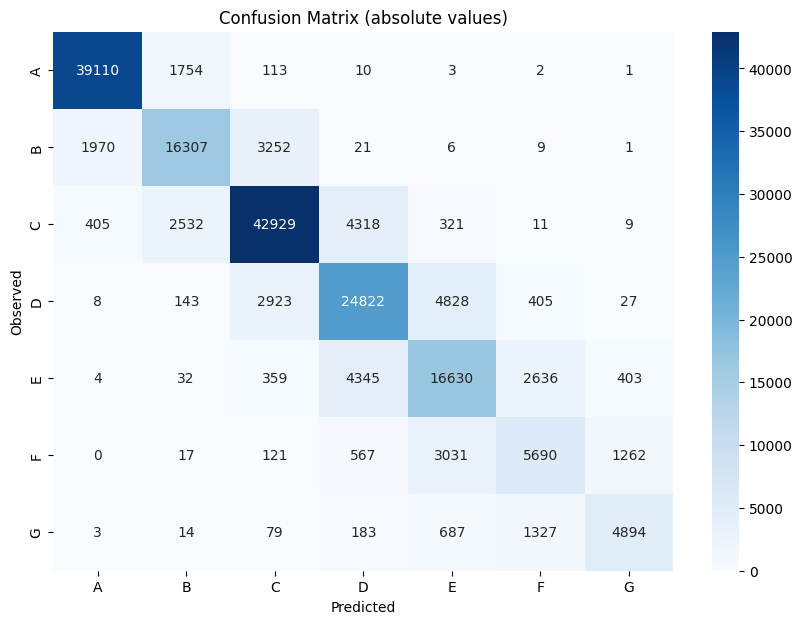

In [178]:
# Improving display of the confusion matrix
plt.figure(figsize=(10, 7))
sns.heatmap(df_confusion_matrix, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix (absolute values)")
plt.xlabel("Predicted")
plt.ylabel("Observed")
plt.show()

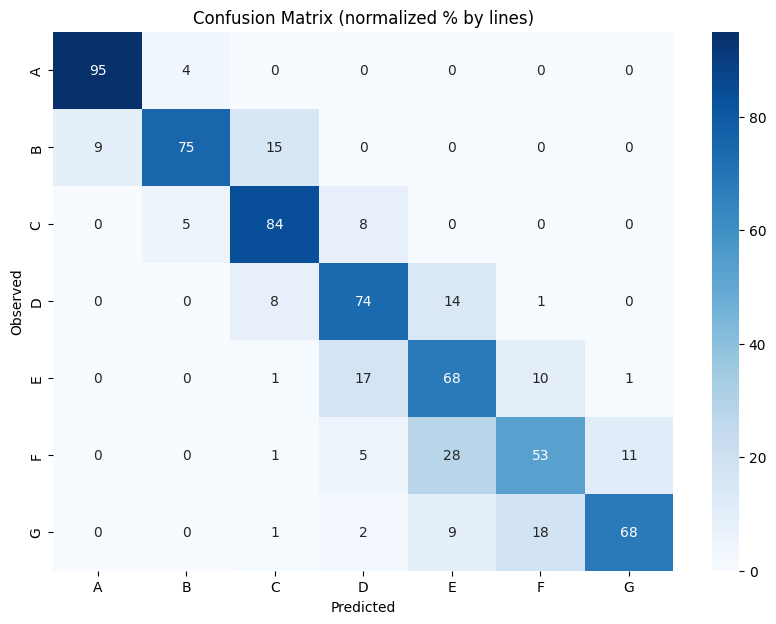

In [179]:
# Improving display of the confusion matrix
plt.figure(figsize=(10, 7))
sns.heatmap(df_confusion_matrix_normalized, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix (normalized % by lines)")
plt.xlabel("Predicted")
plt.ylabel("Observed")
plt.show()

### <a id='toc4_1_3_'></a>[Writing the pipeline to the disk](#toc0_)

In [180]:
# Saving the pipeline to the disk
if not IGNORE:
    joblib.dump(pipeline, "models/pipeline_xgboost_classification.pkl", compress=3)

In [181]:
# Saving label encoder for target.
if not IGNORE:
    joblib.dump(le, "models/label_encoder_target.pkl", compress=3)

In [182]:
# Saving the columns features.
if not IGNORE:
    joblib.dump(
        {
            "quantitative_features": quantitative_features,
            "qualitative_features": qualitative_features,
            "target": target,
        },
        "models/features_target_columns.pkl",
    )

## <a id='toc4_2_'></a>[Features importance](#toc0_)

### <a id='toc4_2_1_'></a>[Feature importance extraction from the XGBoost model](#toc0_)

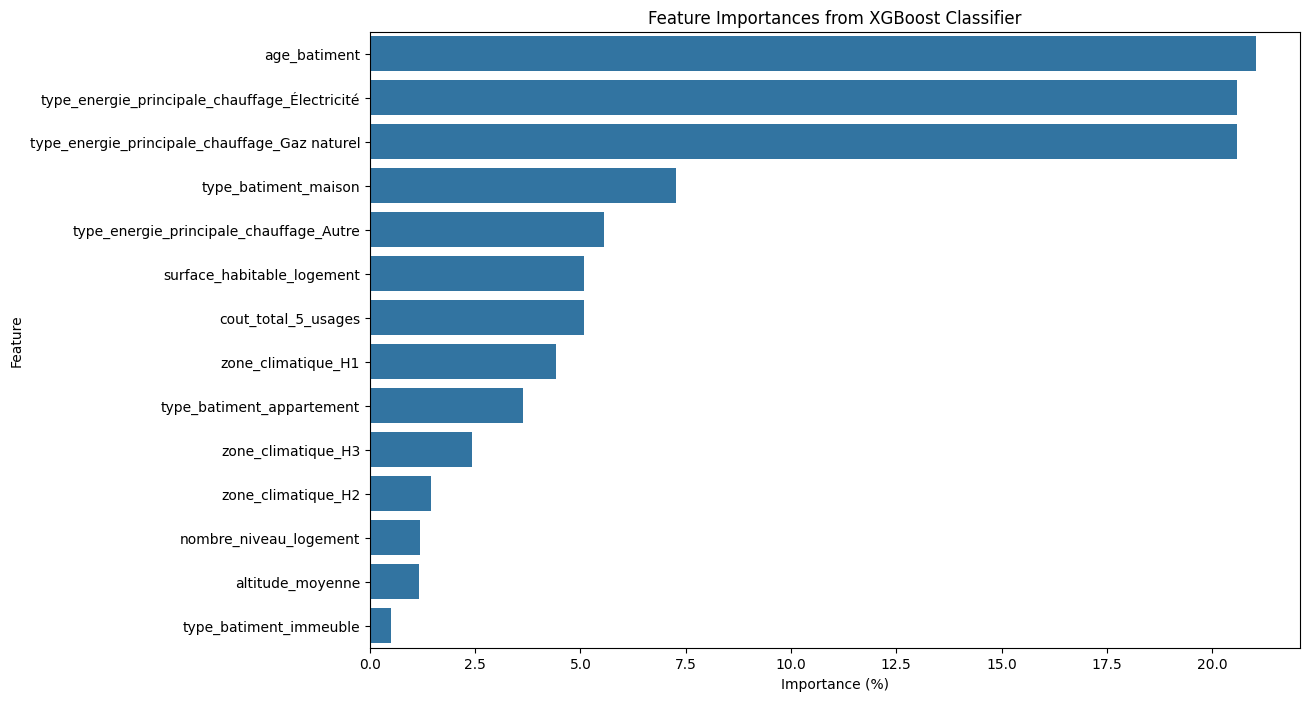

In [183]:
# Creating a DataFrame for better visualization
df_feature_importances = pd.DataFrame(
    {
        "Feature": preprocessed_feature_names,
        "Importance": pipeline.named_steps["model"].feature_importances_ * 100,
    }
)

# Sorting features by importance
df_feature_importances = df_feature_importances.sort_values(
    by="Importance", ascending=False
)

# Plotting feature importances
plt.figure(figsize=(12, 8))
sns.barplot(x="Importance", y="Feature", data=df_feature_importances)
plt.title("Feature Importances from XGBoost Classifier")
plt.xlabel("Importance (%)")
plt.ylabel("Feature")
plt.show()

## <a id='toc4_3_'></a>[Evaluate model with less features](#toc0_)

In [165]:
# Comment the unwanted features.
quantitative_features = [
    "cout_total_5_usages",
    "surface_habitable_logement",
    "nombre_niveau_logement",
    "age_batiment",
    "altitude_moyenne",
]

qualitative_features = [
    "type_energie_principale_chauffage",
    "type_batiment",
    "zone_climatique",
]

target = "etiquette_dpe"

In [166]:
# Separating features and target.
X = df[quantitative_features + qualitative_features]
y = df[target]

In [167]:
# Best model:
clf = XGBClassifier(
    use_label_encoder=False,
    eval_metric="mlogloss",
    colsample_bytree=1,
    learning_rate=0.2,
    max_depth=7,
    min_split_loss=1,
    n_estimators=500,
    reg_alpha=0.5,
    reg_lambda=0.5,
    subsample=0.8,
)

# Train-test split with different random states.
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.3, stratify=y)

# Encoding target label for XGBoost.
le = LabelEncoder()
ytrain_encoded = np.array(le.fit_transform(ytrain))
ytest_encoded = np.array(le.transform(ytest))

preprocessor = ColumnTransformer(
    transformers=[
        (
            "scaler",
            StandardScaler(),
            quantitative_features,
        ),  # Standardize only quantitatives.
        (
            "encoder",
            OneHotEncoder(),
            qualitative_features,
        ),  # OneHot encoding for qualitatives.
    ]
)

# Pipeline
pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("model", clf)])

# Entrainement du modèle.
pipeline.fit(Xtrain, ytrain_encoded)

# Prediction.
predictions = pipeline.predict(Xtest)

# Confusion matrix
conf_matrix = confusion_matrix(ytest_encoded, predictions, normalize="true")

c:\Users\axel-\Documents\Coding\SISE_Enedis_ML_Study\.venv\Lib\site-packages\xgboost\training.py:199: UserWarning: [17:15:41] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [168]:
# Confusion matrix
conf_matrix = confusion_matrix(ytest_encoded, predictions)
conf_matrix_normalized = confusion_matrix(ytest_encoded, predictions, normalize="true")

conf_matrix_normalized = (conf_matrix_normalized * 100).astype(int)

In [169]:
# Data frame conversion and labelisation.
df_confusion_matrix = pd.DataFrame(
    conf_matrix,
    index=le.classes_,
    columns=le.classes_,
)

df_confusion_matrix_normalized = pd.DataFrame(
    conf_matrix_normalized,
    index=le.classes_,
    columns=le.classes_,
)

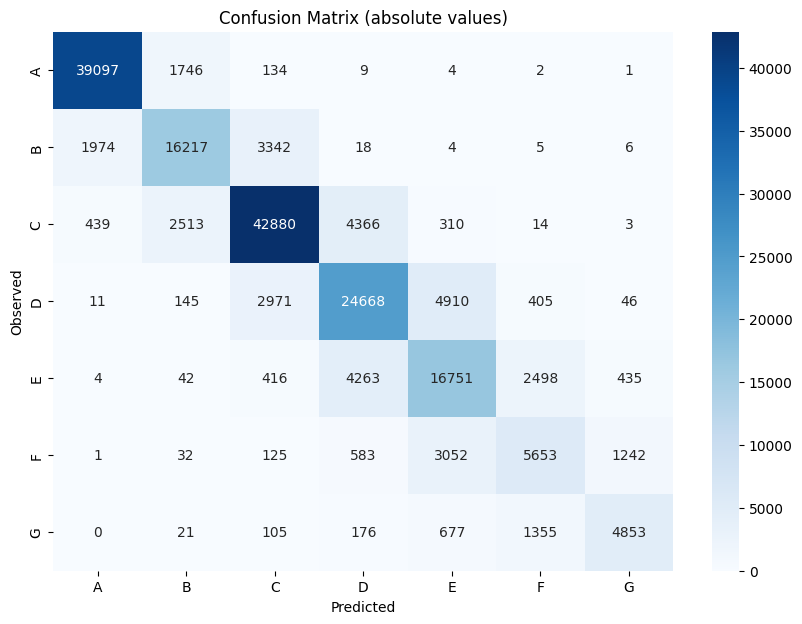

In [170]:
# Improving display of the confusion matrix
plt.figure(figsize=(10, 7))
sns.heatmap(df_confusion_matrix, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix (absolute values)")
plt.xlabel("Predicted")
plt.ylabel("Observed")
plt.show()

In [171]:
# scores:
metrics = {
    "accuracy": accuracy_score(ytest_encoded, predictions),
    "balanced_accuracy": balanced_accuracy_score(ytest_encoded, predictions),
    "f1_score_micro": f1_score(ytest_encoded, predictions, average="micro"),
    "f1_score_macro": f1_score(ytest_encoded, predictions, average="macro"),
    "hamming_loss": hamming_loss(ytest_encoded, predictions),
}

In [172]:
metrics

{'accuracy': 0.796285884025376,
 'balanced_accuracy': 0.7412609855126335,
 'f1_score_micro': 0.796285884025376,
 'f1_score_macro': 0.7461795902348994,
 'hamming_loss': 0.2037141159746239}